In [1]:
import pandas as pd

reviews = pd.read_parquet("../data/processed/reviews.parquet")
listings = pd.read_parquet("../data/processed/listings_panel.parquet")

print("Reviews:", reviews.shape)
print("Listings:", listings.shape)

Reviews: (835772, 17)
Listings: (61543, 87)


In [2]:

# Convert dates into datetime format
reviews["date"] = pd.to_datetime(reviews["date"])

# Filter reviews for Chapter 3
reviews_ch3 = reviews[
    (reviews["language"] == "en") &
    (reviews["word_count"] > 3) &
    (reviews["date"] >= "2024-01-01") &
    (reviews["date"] < "2026-09-01")
].copy()

print("Total reviews:", len(reviews))
print("Reviews after filtering:", len(reviews_ch3))
print("Percentage retained:", round(len(reviews_ch3) / len(reviews) * 100, 1), "%")

print("\nSample reviews:")
print(reviews_ch3[["date", "comments", "host_tier"]].head())


Total reviews: 835772
Reviews after filtering: 399691
Percentage retained: 47.8 %

Sample reviews:
          date                                           comments    host_tier
141 2024-04-27  My family and I stayed for a week and it was t...    pro (10+)
142 2024-12-14  i cant complain for the price it was great onl...    pro (10+)
144 2026-01-20  It a wonderful spot for family to stay while v...    pro (10+)
146 2026-04-16  Great host!  Very supportive and helpful!  Gre...    pro (10+)
174 2024-01-20  Had a nice time there very clean and nice. Onl...  small (2-9)


In [3]:

# Count reviews by host category
print("Reviews by host type:")
print(reviews_ch3["host_tier"].value_counts())

print("\nPercentage by host type:")
print(
    (reviews_ch3["host_tier"]
     .value_counts(normalize=True) * 100)
    .round(1)
)

print("\nReviews with missing host type:")
print(reviews_ch3["host_tier"].isna().sum())


Reviews by host type:
host_tier
pro (10+)      164525
small (2-9)    154301
single          80771
Name: count, dtype: int64

Percentage by host type:
host_tier
pro (10+)      41.2
small (2-9)    38.6
single         20.2
Name: proportion, dtype: float64

Reviews with missing host type:
94


In [4]:

# Look at 10 random customer reviews
sample_reviews = reviews_ch3[
    ["comments", "host_tier", "city"]
].sample(10, random_state=42)

pd.set_option("display.max_colwidth", 250)

display(sample_reviews)


,comments,host_tier,city
675141,The location of this property (unit 10) was perfect. Walk out the door and you are at the pool (heated in cooler months) walk a little further and you are on the beach. In hind site I would have Ubered here from the airport. You can walk to the...,pro (10+),Lauderdale By The Sea
807636,"Wow, I was absolutely blown away by the property. My guests were very happy. Cj was very attentive and responsive. Anytime I reached out to him. My birthday was a great success thank you guys. Your property is amazing and I look forward to doing ...",pro (10+),Hollywood
308560,"We had a wonderful stay and had to extend due to an unexpected situation. Ilan made it possible for us to stay and not have to move units which we really appreciated. He was communicative and helpful. Wayne, the property manager onsite was helpfu...",pro (10+),Pompano Beach
752594,"Great, comfortable place. Decorated well , equipped well, and overall nice. Only Con were there are like 2 or 3 cameras in the backyard. wasn't an issue for me, but may make some uncomfortable, especially the one pointing at the hot tub.",single,Fort Lauderdale
737743,"This beach hotel is very well maintained, cute, and the staff is wonderful. The location is great! Notes: - the parking is $30 per 24 hrs - there is a pesticide/air freshener smell in the room but I was able to open the windows (it was winter)",small (2-9),Hollywood
161669,It felt right at home. Had all of the things you could want for a long stay. The mini put-put course was an unexpected pleasure. The bed was amazingly comfortable. It had all of the amenities in the kitchen that you could desire. It’s strange how...,pro (10+),Hollywood
47409,All around great stay I will definitely be back soon. I enjoyed my trip.,small (2-9),Hallandale Beach
116559,Great and easy stay. Super host. Wonderful getaway.,small (2-9),Dania Beach
176858,Our stay was fantastic,pro (10+),Pompano Beach
460339,The house is beautiful and very comfortable. It has everything you need. The pool is gorgeous and the backyard is private. We loved having the covered option outside as well. Ronny was extremely responsive and helpful throughout our stay. I woul...,small (2-9),Pompano Beach


In [5]:

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

# Test VADER on three example reviews
examples = [
    "Amazing location, beautiful property, and wonderful host!",
    "The property was okay, nothing particularly special.",
    "The room was dirty, the host was unresponsive, and the stay was terrible."
]

for review in examples:
    score = analyzer.polarity_scores(review)
    print(review)
    print("Compound sentiment score:", score["compound"])
    print()


Amazing location, beautiful property, and wonderful host!
Compound sentiment score: 0.9134

The property was okay, nothing particularly special.
Compound sentiment score: -0.1468

The room was dirty, the host was unresponsive, and the stay was terrible.
Compound sentiment score: -0.7184



In [6]:

import time

# Start timing the analysis
start_time = time.time()

# Calculate sentiment for every review
reviews_ch3["sentiment_score"] = reviews_ch3["comments"].fillna("").apply(
    lambda text: analyzer.polarity_scores(str(text))["compound"]
)

# Classify reviews
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

reviews_ch3["sentiment"] = reviews_ch3["sentiment_score"].apply(classify_sentiment)

# Show overall results
print("Overall sentiment distribution:")
print(reviews_ch3["sentiment"].value_counts())

print("\nSentiment percentages:")
print((reviews_ch3["sentiment"].value_counts(normalize=True) * 100).round(2))

print("\nAverage sentiment score:")
print(round(reviews_ch3["sentiment_score"].mean(), 4))

print("\nProcessing time (seconds):")
print(round(time.time() - start_time, 2))


Overall sentiment distribution:
sentiment
Positive    382845
Negative     10542
Neutral       6304
Name: count, dtype: int64

Sentiment percentages:
sentiment
Positive    95.79
Negative     2.64
Neutral      1.58
Name: proportion, dtype: float64

Average sentiment score:
0.7942

Processing time (seconds):
67.94


In [7]:

# Compare sentiment across host categories

host_sentiment = (
    reviews_ch3.dropna(subset=["host_tier"])
    .groupby("host_tier", observed=True)
    .agg(
        review_count=("sentiment_score", "size"),
        average_sentiment=("sentiment_score", "mean"),
        median_sentiment=("sentiment_score", "median"),
        positive_pct=("sentiment", lambda x: (x == "Positive").mean() * 100),
        negative_pct=("sentiment", lambda x: (x == "Negative").mean() * 100)
    )
    .round(3)
    .sort_values("average_sentiment", ascending=False)
)

display(host_sentiment)


,review_count,average_sentiment,median_sentiment,positive_pct,negative_pct
host_tier,,,,,
single,80771,0.826,0.913,97.050,1.675
small (2-9),154301,0.805,0.901,96.281,2.223
pro (10+),164525,0.768,0.881,94.697,3.500


In [8]:
# Step 8: Compare average sentiment at the listing level

listing_sentiment = (
    reviews_ch3.dropna(subset=["host_tier"])
    .groupby(["listing_id", "host_tier"], observed=True)
    .agg(
        review_count=("sentiment_score", "size"),
        avg_sentiment=("sentiment_score", "mean")
    )
    .reset_index()
)

# Keep listings with at least 5 reviews
listing_sentiment_5 = listing_sentiment[
    listing_sentiment["review_count"] >= 5
].copy()

# Compare host categories
listing_comparison = (
    listing_sentiment_5
    .groupby("host_tier", observed=True)
    .agg(
        listing_count=("listing_id", "nunique"),
        average_sentiment=("avg_sentiment", "mean"),
        median_sentiment=("avg_sentiment", "median")
    )
    .round(3)
    .sort_values("average_sentiment", ascending=False)
)

display(listing_comparison)

print("Listings with at least 5 reviews:",
      len(listing_sentiment_5))


,listing_count,average_sentiment,median_sentiment
host_tier,,,
single,2359,0.819,0.841
small (2-9),4143,0.800,0.821
pro (10+),5310,0.758,0.784


Listings with at least 5 reviews: 11812


In [9]:
# Step 9: Validate sentiment against listing ratings

# Select the latest listing snapshot
sep_listings = listings[
    listings["snapshot_date"] == "2026-09-22"
][["id", "review_scores_rating"]].copy()

# Merge listing-level sentiment with Airbnb ratings
validation = listing_sentiment_5.merge(
    sep_listings,
    left_on="listing_id",
    right_on="id",
    how="inner"
)

# Remove listings without an Airbnb rating
validation = validation.dropna(
    subset=["review_scores_rating"]
)

# Calculate correlation
correlation = validation[
    ["avg_sentiment", "review_scores_rating"]
].corr().iloc[0, 1]

print("Listings included in validation:", len(validation))
print("Correlation between sentiment and Airbnb ratings:",
      round(correlation, 3))

print("\nSample comparison:")
display(validation[
    ["host_tier", "avg_sentiment", "review_scores_rating"]
].head())


Listings included in validation: 9511
Correlation between sentiment and Airbnb ratings: 0.689

Sample comparison:


,host_tier,avg_sentiment,review_scores_rating
0,small (2-9),0.883537,5.00
1,single,0.792205,4.82
2,small (2-9),0.856663,4.85
3,small (2-9),0.799562,4.80
4,pro (10+),0.831454,4.75


In [10]:
# Step 10: Identify common customer review topics

import re

topics = {
    "Cleanliness": r"\b(?:clean|cleanliness|dirty|spotless|filthy|dusty)\b",
    "Location": r"\b(?:location|beach|walkable|neighborhood|nearby|airport)\b",
    "Communication": r"\b(?:host|communication|responsive|helpful|check.in|staff)\b",
    "Amenities": r"\b(?:pool|kitchen|wifi|parking|bed|bathroom|hot tub)\b",
    "Value": r"\b(?:price|expensive|worth|value|cost|affordable|overpriced)\b"
}

# Check whether each review mentions a topic
for topic, pattern in topics.items():
    reviews_ch3[topic] = (
        reviews_ch3["comments"]
        .fillna("")
        .str.contains(pattern, flags=re.IGNORECASE, regex=True)
    )

# Calculate how frequently each topic appears
topic_results = pd.DataFrame({
    "Topic": list(topics.keys()),
    "Review Count": [
        int(reviews_ch3[topic].sum()) for topic in topics
    ],
    "Percentage": [
        reviews_ch3[topic].mean() * 100 for topic in topics
    ]
})

topic_results = topic_results.sort_values(
    "Review Count", ascending=False
)

display(topic_results.round(2))


,Topic,Review Count,Percentage
2,Communication,157325,39.36
1,Location,154300,38.60
0,Cleanliness,123516,30.90
3,Amenities,100396,25.12
4,Value,20736,5.19


In [11]:
# Step 11: Analyze topics in negative reviews

negative_reviews = reviews_ch3[
    reviews_ch3["sentiment"] == "Negative"
].copy()

print("Total negative reviews:", len(negative_reviews))

# Percentage of negative reviews mentioning each topic
negative_topics = pd.DataFrame({
    "Topic": list(topics.keys()),
    "Negative Review Mentions": [
        int(negative_reviews[topic].sum())
        for topic in topics
    ],
    "Percentage of Negative Reviews": [
        negative_reviews[topic].mean() * 100
        for topic in topics
    ]
})

negative_topics = negative_topics.sort_values(
    "Negative Review Mentions",
    ascending=False
)

print("\nTopics mentioned in negative reviews:")
display(negative_topics.round(2))

# Compare negative review rates by host type
print("\nNegative review rate by host type:")
negative_rate = (
    reviews_ch3.dropna(subset=["host_tier"])
    .groupby("host_tier", observed=True)["sentiment"]
    .apply(lambda x: (x == "Negative").mean() * 100)
    .round(2)
)

display(negative_rate)


Total negative reviews: 10542

Topics mentioned in negative reviews:


,Topic,Negative Review Mentions,Percentage of Negative Reviews
3,Amenities,5077,48.16
2,Communication,4114,39.02
0,Cleanliness,3558,33.75
1,Location,2562,24.30
4,Value,1236,11.72



Negative review rate by host type:


host_tier
single         1.68
small (2-9)    2.22
pro (10+)      3.50
Name: sentiment, dtype: float64

In [12]:

# Step 12: Examine examples of negative customer reviews

pd.set_option("display.max_colwidth", 350)

# Random sample of negative reviews
negative_sample = negative_reviews[
    ["comments", "host_tier", "city", "sentiment_score"]
].sample(15, random_state=42)

display(negative_sample)


,comments,host_tier,city,sentiment_score
655518,"It was ok. Good location. Pool was tiny, not very clean and with no beach chair unfortunately. There’s no natural light. The wasn’t dryer would dry so you had a pile of wet clothes to lay out to dry. Also it wasn’t well insulated so it was very warm. All in all it was OK.",small (2-9),Oakland Park,-0.2481
356349,"(Safety Alert!!) They pad lock the gates that go to the cars at 5:00 and make customers walk all the around to the front gate that is never locked because the lock is broken and the gate won’t shut. Also, there’s no lock or chain on the inside of room door so anyone that has the code can walk in at any time. (Terrible Work ethic and customer s...",pro (10+),Hollywood,-0.1739
690832,"The unit we got was not the unit that was advertised. Was supposed to have 3 beds and sofa bed on ground floor, got 2 beds and no sofa bed (and no extra bedding) on 3rd floor. Signs of wear and tear alongside new renovations. Host was communicative at first then went radio silent when I reached out. Had to make do but was a hardship. Location w...",pro (10+),Fort Lauderdale,-0.4118
686618,"When I entered the home I thought it was nice. But for the price it was not. I always take pictures of homes prior to moving my family in. The living room Ceiling is water damaged, game room pool sticks were broken, no curtains in hallway neighbors can look into home, dirty mop, dirty vents, broken tiles in bathroom, shower not working properly...",small (2-9),Fort Lauderdale,-0.9889
631689,"DO NOT BOOK THIS HOME! RUNNNNN. You will regret it. The customer service was absolutely horrible. The owner was rude and obnoxious. He sat and watched my family on the camera from the moment we arrived. There is a vacant field next-door to the property that didn’t display a no parking sign therefore, some of my loved ones parked in the field,...",pro (10+),Coconut Creek,-0.9744
15526,"There is no free parking, $18.00 a day",small (2-9),Fort Lauderdale,-0.4023
322571,The lay out of the house was great but the pillows was dirty,pro (10+),Fort Lauderdale,-0.3182
751587,"I feel like the pictures was AI, there was no face towels, I had to go purchase towels and toilet paper. There was 1 roll of paper towels, one roll of toilet paper in each bathroom. The pool was dirty had to ask to have it cleaned. House not as advertised for the price I paid.",pro (10+),Hollywood,-0.3818
240366,"This property looks old & is not being maintained well in comparison to Airbnb photos. Landscaping was not maintained. Statues & fixtures by the pool need pressure washing. Front fountain was full of debris & algae. Outdoor seating was covered in debris & cushions were in a storage box but too worn for use. The speaker system is outdated, host ...",single,Fort Lauderdale,-0.9546
620446,It is not good .,single,Hallandale Beach,-0.3412


/tmp/ipykernel_4393/2481405431.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_sentiment.round(3))


,month,review_count,avg_sentiment,negative_pct
0,2025-01-01,12403,0.790,2.790
1,2025-02-01,13005,0.796,2.491
2,2025-03-01,16970,0.799,2.546
3,2025-04-01,14273,0.801,2.501
4,2025-05-01,12879,0.794,2.446
5,2025-06-01,12146,0.798,2.659
6,2025-07-01,12317,0.800,2.598
7,2025-08-01,11088,0.792,2.715
8,2025-09-01,8980,0.787,2.895
9,2025-10-01,10161,0.789,2.628


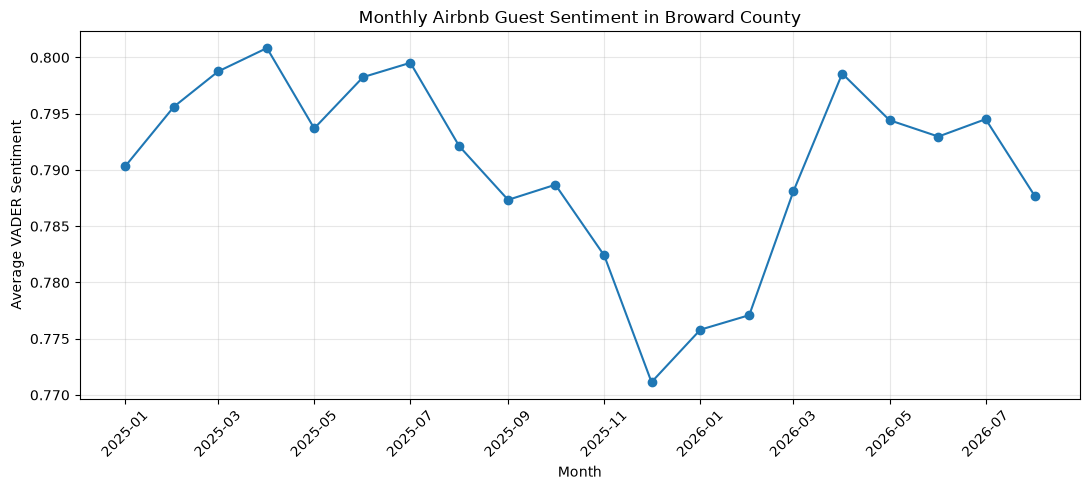

In [13]:
# Step 13: Monthly sentiment trends

import matplotlib.pyplot as plt

# Use 2025 onward for trend analysis
trends = reviews_ch3[
    reviews_ch3["date"] >= "2025-01-01"
].copy()

# Create month variable
trends["month"] = trends["date"].dt.to_period("M")

# Calculate monthly sentiment
monthly_sentiment = (
    trends.groupby("month")
    .agg(
        review_count=("sentiment_score", "size"),
        avg_sentiment=("sentiment_score", "mean"),
        negative_pct=(
            "sentiment",
            lambda x: (x == "Negative").mean() * 100
        )
    )
    .reset_index()
)

monthly_sentiment["month"] = (
    monthly_sentiment["month"].dt.to_timestamp()
)

display(monthly_sentiment.round(3))

# Plot average sentiment over time
plt.figure(figsize=(11, 5))
plt.plot(
    monthly_sentiment["month"],
    monthly_sentiment["avg_sentiment"],
    marker="o"
)

plt.title("Monthly Airbnb Guest Sentiment in Broward County")
plt.xlabel("Month")
plt.ylabel("Average VADER Sentiment")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


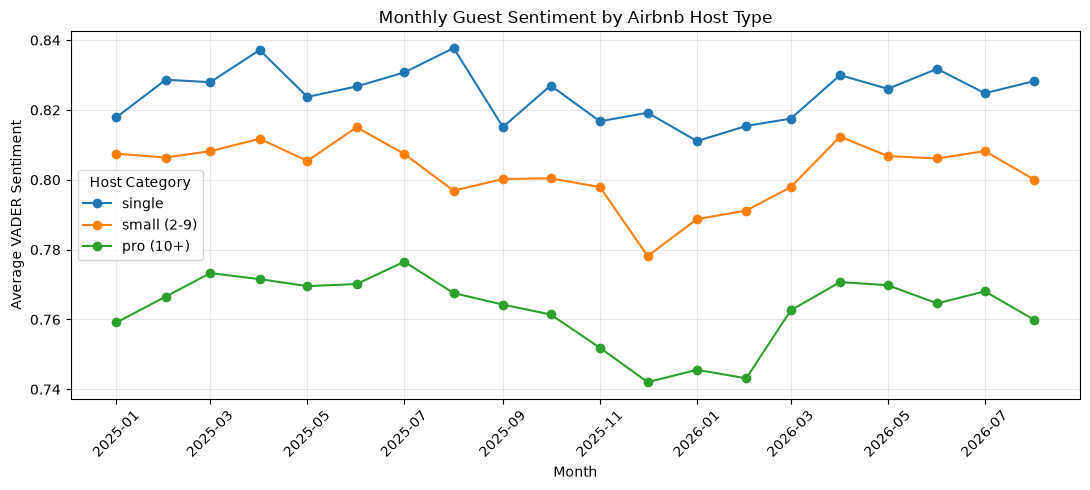

host_tier
single         0.825
small (2-9)    0.802
pro (10+)      0.763
Name: avg_sentiment, dtype: float64

In [14]:
# Step 14: Monthly sentiment trends by host type

host_trends = (
    trends.dropna(subset=["host_tier"])
    .groupby(["month", "host_tier"], observed=True)
    .agg(
        review_count=("sentiment_score", "size"),
        avg_sentiment=("sentiment_score", "mean")
    )
    .reset_index()
)

host_trends["month"] = host_trends["month"].dt.to_timestamp()

# Plot a separate line for each host category
plt.figure(figsize=(11, 5))

for host_type, group in host_trends.groupby("host_tier", observed=True):
    plt.plot(
        group["month"],
        group["avg_sentiment"],
        marker="o",
        label=host_type
    )

plt.title("Monthly Guest Sentiment by Airbnb Host Type")
plt.xlabel("Month")
plt.ylabel("Average VADER Sentiment")
plt.legend(title="Host Category")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Display average sentiment across the trend period
display(
    host_trends.groupby("host_tier", observed=True)["avg_sentiment"]
    .mean()
    .round(3)
)


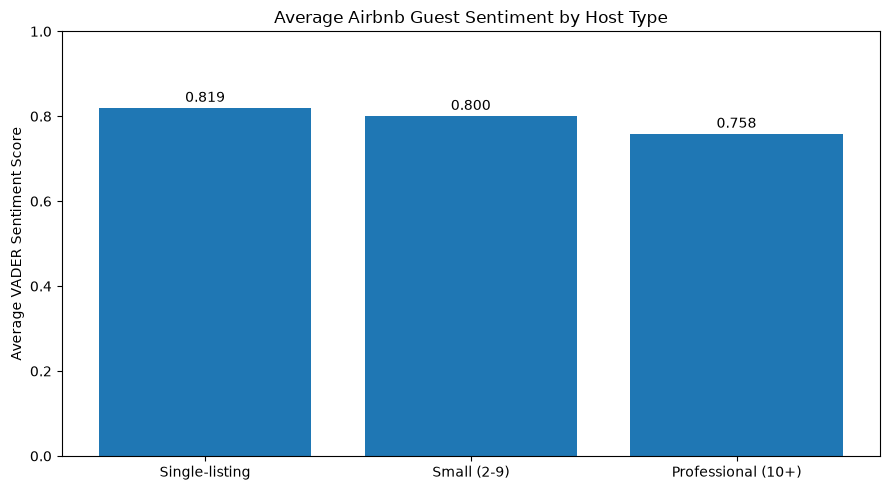

In [15]:
# Step 15: Final chart - Sentiment by host type

import matplotlib.pyplot as plt
from pathlib import Path

# Create a folder for our charts
figures_dir = Path("figures/ch3")
figures_dir.mkdir(parents=True, exist_ok=True)

# Use the listing-level results from Step 8
chart_data = listing_comparison.reindex([
    "single", "small (2-9)", "pro (10+)"
])

plt.figure(figsize=(9, 5))

bars = plt.bar(
    ["Single-listing", "Small (2-9)", "Professional (10+)"],
    chart_data["average_sentiment"]
)

plt.title("Average Airbnb Guest Sentiment by Host Type")
plt.ylabel("Average VADER Sentiment Score")
plt.ylim(0, 1)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{bar.get_height():.3f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(figures_dir / "ch3_sentiment_by_host.png",
            dpi=300, bbox_inches="tight")
plt.show()


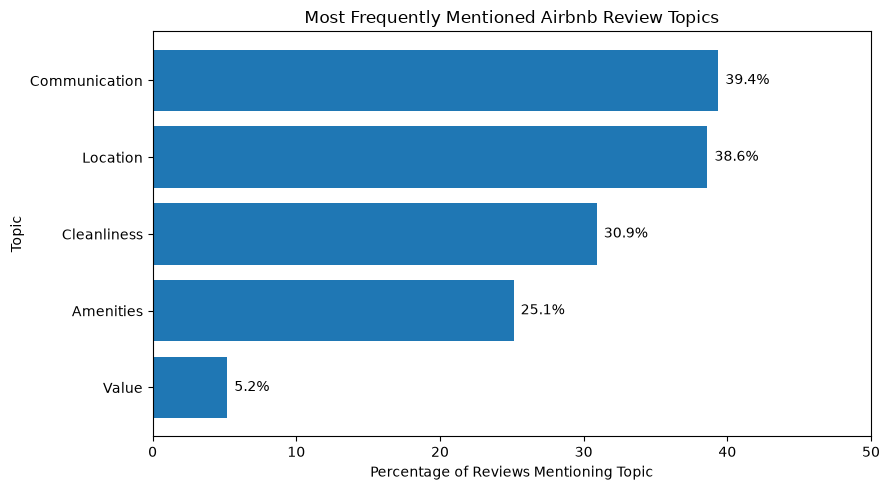

In [16]:
# Step 16: Final chart - Most mentioned review topics

# Use results from Step 10
chart_topics = topic_results.sort_values(
    "Percentage", ascending=True
)

plt.figure(figsize=(9, 5))

bars = plt.barh(
    chart_topics["Topic"],
    chart_topics["Percentage"]
)

plt.title("Most Frequently Mentioned Airbnb Review Topics")
plt.xlabel("Percentage of Reviews Mentioning Topic")
plt.ylabel("Topic")
plt.xlim(0, 50)

for bar in bars:
    plt.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    figures_dir / "ch3_review_topics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


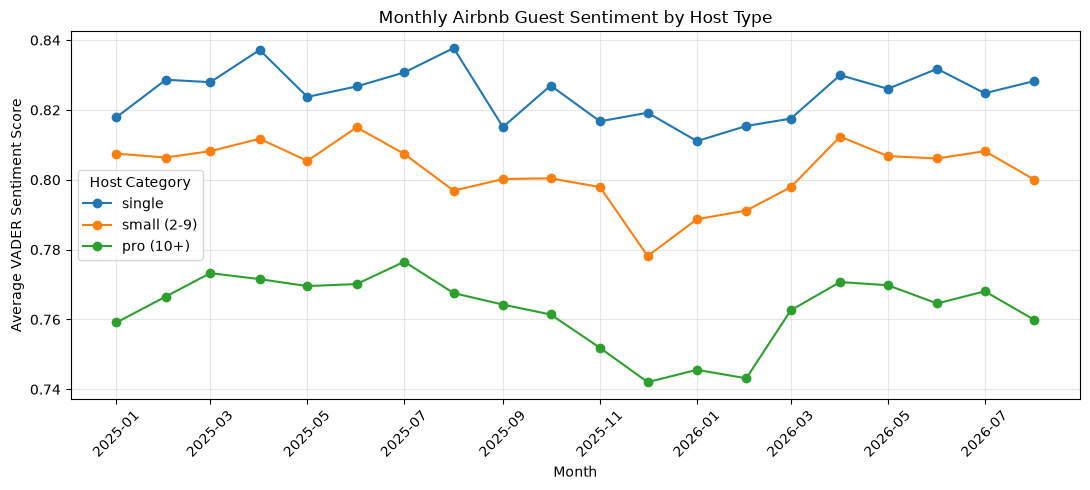

In [17]:
# Step 17: Save monthly sentiment trends by host type

plt.figure(figsize=(11, 5))

for host_type, group in host_trends.groupby("host_tier", observed=True):
    plt.plot(
        group["month"],
        group["avg_sentiment"],
        marker="o",
        label=host_type
    )

plt.title("Monthly Airbnb Guest Sentiment by Host Type")
plt.xlabel("Month")
plt.ylabel("Average VADER Sentiment Score")
plt.legend(title="Host Category")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    figures_dir / "ch3_monthly_sentiment_by_host.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Export for the dashboard

Small summary tables used by the dashboard's "What guests say" page (`dashboard/scripts/build_data.py` copies this file). Nothing new is computed beyond the steps above.

In [18]:
import json
tiers = ["single", "small (2-9)", "pro (10+)"]
known = reviews_ch3.dropna(subset=["host_tier"])
neg_topic_by_tier = (negative_reviews.dropna(subset=["host_tier"]).groupby("host_tier", observed=True)[list(topics)].mean() * 100)
top_cities = ["Fort Lauderdale", "Hollywood", "Pompano Beach", "Hallandale Beach", "Deerfield Beach",
              "Wilton Manors", "Lauderdale By The Sea", "Dania Beach", "Oakland Park"]
city_tier = (known[known.city.isin(top_cities)].groupby(["city", "host_tier"], observed=True)
             .agg(reviews=("sentiment_score", "size"), mean=("sentiment_score", "mean"),
                  negative_pct=("sentiment", lambda x: (x == "Negative").mean() * 100)).reset_index())
export = {
    "reviews": int(len(reviews_ch3)), "share_of_file": len(reviews_ch3) / len(reviews),
    "sentiment_pct": (reviews_ch3.sentiment.value_counts(normalize=True) * 100).round(2).to_dict(),
    "mean_sentiment": round(float(reviews_ch3.sentiment_score.mean()), 4),
    "by_tier_reviews": host_sentiment.reindex(tiers).reset_index().round(4).to_dict("records"),
    "by_tier_listings": listing_comparison.reindex(tiers).reset_index().round(4).to_dict("records"),
    "listings_5plus": int(len(listing_sentiment_5)),
    "rating_correlation": round(float(correlation), 3), "rating_listings": int(len(validation)),
    "topics": topic_results.round(2).to_dict("records"),
    "negative_reviews": int(len(negative_reviews)),
    "negative_topics": negative_topics.round(2).to_dict("records"),
    "negative_topics_by_tier": neg_topic_by_tier.reindex(tiers).round(2).reset_index().to_dict("records"),
    "monthly": monthly_sentiment.assign(month=monthly_sentiment.month.dt.strftime("%Y-%m")).round(4).to_dict("records"),
    "monthly_by_tier": host_trends.assign(month=host_trends.month.dt.strftime("%Y-%m")).round(4).to_dict("records"),
    "city_tier": city_tier.round(4).to_dict("records"),
}
(figures_dir / "dashboard_guests.json").write_text(json.dumps(export, indent=1))
print("wrote", figures_dir / "dashboard_guests.json")

wrote figures/ch3/dashboard_guests.json
